In [1]:
from src.ui.backend.DisplayAPI import DisplayAPI
from src.util.logger import Logger
from src.util.prompt import Prompt
import src.data_preprocessing.image_preprocessing as img_pre
from src.util.system_status import SystemStatus


In [2]:
# Create the backend API that communicates with the UI
backend= DisplayAPI()

# Start the API thread that will connect to and communicate with the UI
backend.start()
Logger.info(f"Server running: {backend.server_running()}")

17:26:08 [INFO    ]: Serving UI from: /home/chris/capstone/PlantQA/src/ui/web
17:26:08 [INFO    ]: HTML file: /home/chris/capstone/PlantQA/src/ui/web/ui.html
17:26:08 [INFO    ]: CSS file: /home/chris/capstone/PlantQA/src/ui/web/style/main.css
17:26:08 [INFO    ]: UI running at: http://127.0.0.1:8000/ui.html
17:26:08 [INFO    ]: Server running: True


INFO:     Started server process [24457]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://127.0.0.1:8000 (Press CTRL+C to quit)


INFO:     127.0.0.1:54452 - "GET /ui.html HTTP/1.1" 200 OK
INFO:     127.0.0.1:54456 - "GET /images/leaves2.png HTTP/1.1" 200 OK
INFO:     127.0.0.1:54452 - "GET /style/main.css HTTP/1.1" 200 OK
INFO:     127.0.0.1:54460 - "GET /scripts/fast_posting.js HTTP/1.1" 200 OK
INFO:     127.0.0.1:54476 - "GET /scripts/fast_websockets.js HTTP/1.1" 200 OK
INFO:     127.0.0.1:54490 - "GET /scripts/history.js HTTP/1.1" 200 OK
INFO:     127.0.0.1:54492 - "GET /scripts/general.js HTTP/1.1" 200 OK
INFO:     127.0.0.1:54456 - "GET /scripts/navigation.js HTTP/1.1" 200 OK
INFO:     127.0.0.1:54452 - "GET /.well-known/appspecific/com.chrome.devtools.json HTTP/1.1" 404 Not Found
INFO:     127.0.0.1:54492 - "GET /style/panels.css HTTP/1.1" 200 OK
INFO:     127.0.0.1:54476 - "GET /style/question_panel.css HTTP/1.1" 200 OK
INFO:     127.0.0.1:54490 - "GET /style/header.css HTTP/1.1" 200 OK
INFO:     127.0.0.1:54460 - "GET /style/answer_panel.css HTTP/1.1" 200 OK
INFO:     127.0.0.1:54456 - "GET /style/layout

INFO:     127.0.0.1:54500 - "WebSocket /status" [accepted]
INFO:     connection open


17:26:11 [INFO    ]: Status websocket connection made!
INFO:     127.0.0.1:54476 - "GET /favicon.ico HTTP/1.1" 404 Not Found


INFO:     127.0.0.1:54510 - "WebSocket /answer" [accepted]
INFO:     connection open


17:26:11 [INFO    ]: Answer websocket connection made!
17:26:18 [DEBUG   ]: Enqueuing prompt: dddd
INFO:     127.0.0.1:52064 - "POST /ask HTTP/1.1" 200 OK
17:26:18 [INFO    ]: [JS] Entry added to history for ID: 16c9a09e5d314636b88e2fc883ebdc88
INFO:     127.0.0.1:52064 - "POST /log HTTP/1.1" 200 OK


In [3]:
# After starting the server, you open the src/ui/web/ui.html file to launch the UI

18:01:42 [DEBUG   ]: Enqueuing prompt: asdfasdf
INFO:     127.0.0.1:38594 - "POST /ask HTTP/1.1" 200 OK


17:35:47 [INFO    ]: Question: aaaaaaaaaa adddddddddddddddddddddddda aaaaaaaaa aa a a 


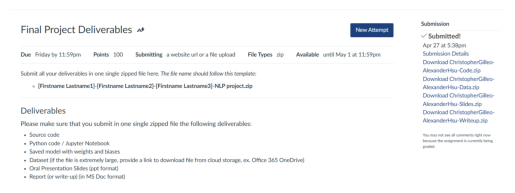

In [10]:
# After the API has confirmed the connection with "[JS] UI Initialized!"
# you can send a prompt.  Upload an image, type a question, and press the ask question button

# Confirm you received the prompt on the server side
# (you should see a debug log that says "Enqueuing prompt: {qustion}")

# After receiving a prompt, the server puts the prompt into a queue
# Take the prompt out of the queue
prompt= backend.get_prompt()
Logger.info(f"Question: {prompt.question}")
img_pre.show_image(prompt.image)

backend.set_status(SystemStatus.PROCESSING)

In [11]:
backend.send_answer(
    "This appears to be a pine tree, an evergreen conifer recognized by its long, slender needles and woody cones. Pine trees are found in many regions and typically remain green throughout the year.",
    0.81,
    prompt.job_id
)
backend.set_status(SystemStatus.READY)

17:35:58 [DEBUG   ]: Enqueuing prompt: aaaaaaaaaa adddddddddddddddddddddddda aaaaaaaaa aa a a 
INFO:     127.0.0.1:58702 - "POST /ask HTTP/1.1" 200 OK
17:35:58 [INFO    ]: [JS] Entry added to history for ID: 5b5d2f3208e540b4b92fdc3279eb1463
INFO:     127.0.0.1:58702 - "POST /log HTTP/1.1" 200 OK
17:36:01 [DEBUG   ]: Enqueuing prompt: aaaaaaaaaa adddddddddddddddddddddddda aaaaaaaaa aa a a 
INFO:     127.0.0.1:58702 - "POST /ask HTTP/1.1" 200 OK
17:36:01 [INFO    ]: [JS] Entry added to history for ID: a71c79fd68a347d2b39d5351408e4066
INFO:     127.0.0.1:58702 - "POST /log HTTP/1.1" 200 OK
17:36:04 [DEBUG   ]: Enqueuing prompt: aaaaaaaaaa adddddddddddddddddddddddda aaaaaaaaa aa a a 
INFO:     127.0.0.1:58702 - "POST /ask HTTP/1.1" 200 OK
17:36:04 [INFO    ]: [JS] Entry added to history for ID: 96d30fff255f496da585f2d6d3516701
INFO:     127.0.0.1:58702 - "POST /log HTTP/1.1" 200 OK


In [ ]:
backend.stop()

In [1]:
from src.util.history_tracker import HISTORY
from src.util.general import make_random_np_img
import random
import uuid

questions = [
    "What plant is shown in this image?",
    "Why are the edges of these leaves turning brown?",
    "Does this plant show any signs of disease?",
    "How often should this plant be watered?",
    "What could be causing the yellowing of these leaves?"
]

answers = [
    "This appears to be a pine tree, identifiable by its needle-like leaves and woody stem.",
    "The browning may be caused by underwatering, excessive sunlight, or nutrient deficiencies.",
    "The leaves show possible signs of fungal infection, though further inspection would be needed to confirm.",
    "Most houseplants benefit from watering when the top inch or two of soil feels dry.",
    "Yellowing leaves can result from overwatering, poor drainage, or a lack of essential nutrients."
]

19:48:02 [INFO    ]: Q/A history recorded to: /home/chris/capstone/PlantQA/data/history
19:48:02 [INFO    ]: Loading existing history file: /home/chris/capstone/PlantQA/data/history/history_09_10_2026.json
19:48:02 [INFO    ]: Loading image history...
19:48:02 [INFO    ]: History initialized!


In [2]:
img= make_random_np_img()
job_id= str(uuid.uuid4().hex)
question = random.choice(questions)
answer = random.choice(answers)
confidence= round(random.random(), 2)

In [3]:
HISTORY.add(job_id, question, img)

In [4]:
HISTORY.update_answer(job_id, answer, confidence)